# Reachable — ML core walkthrough

Predict whether an inbound lead converts from how it was handled, on UCI Bank Marketing (dataset 222). Seed 42. Run `python data/download.py` first.

In [1]:
import sys, json
sys.path.insert(0, '../src')
import pandas as pd
from IPython.display import Image, Markdown, display
from data import load, SEED
X, y = load()
print(X.shape, 'positive rate', round(y.mean(), 3))

(41188, 21) positive rate 0.113


## 1. The data is imbalanced

About 11% positives, so always predicting "no" scores ~89% accuracy. We lead with PR-AUC instead.

In [2]:
y.value_counts(normalize=True).rename({0: 'no', 1: 'yes'})

y
no     0.887346
yes    0.112654
Name: proportion, dtype: float64

## 2. The `pdays` sentinel

`pdays == 999` means *never contacted before*. It is split into a `never_contacted` flag and a real-gap column (missing for never-contacted rows).

In [3]:
pd.DataFrame({'share_of_rows': X['never_contacted'].value_counts(normalize=True),
              'conversion_rate': y.groupby(X['never_contacted']).mean()})

,share_of_rows,conversion_rate
never_contacted,,
0,0.036783,0.638284
1,0.963217,0.092582


## 3. The leakage trap: `duration`

Call length is only known *after* the call ends, and it tracks the outcome almost directly. Conversion by duration quintile:

In [4]:
y.groupby(pd.qcut(X['duration'], 5), observed=True).mean().round(3)

duration
(-0.001, 89.0]     0.005
(89.0, 146.0]      0.032
(146.0, 222.0]     0.073
(222.0, 368.0]     0.125
(368.0, 4918.0]    0.330
Name: y, dtype: float64

So we train **Model A** without `duration` (the headline) and **Model B** with it (only to measure the inflation).

## 4. Train and evaluate everything

Four models (majority baseline, logistic regression, random forest, gradient boosting), 5-fold stratified CV on the 80% train split, a single look at the 20% test split, isotonic calibration of the best model, a temporal-split check, and permutation importance. About 2 minutes.

In [5]:
import os
os.environ.setdefault('LOKY_MAX_CPU_COUNT', str(os.cpu_count()))
import contextlib, io, run
with contextlib.redirect_stdout(io.StringIO()):
    run.main()
display(Markdown(open('../results/results_table.md').read()))

C:\Users\edjjo\AppData\Roaming\Python\Python312\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\edjjo\AppData\Roaming\Python\Python312\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Program Files\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Program Files\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Program Files\Python312\Lib\subprocess.py", line 1538, in _execute_ch

Random split: train 32,950 / test 8,238 (test positive rate 0.113). Temporal split: train 32,950 / test 8,238 (train positive rate 0.064, test positive rate 0.308).

| variant             | model                        |   cv_roc_auc |   cv_pr_auc |   roc_auc |   pr_auc |   brier |   threshold |   precision |   recall |    f1 |   accuracy |
|:--------------------|:-----------------------------|-------------:|------------:|----------:|---------:|--------:|------------:|------------:|---------:|------:|-----------:|
| A (no duration)     | Majority baseline            |        0.500 |       0.113 |     0.500 |    0.113 |   0.113 |       0.500 |       0.000 |    0.000 | 0.000 |      0.887 |
| A (no duration)     | Logistic regression          |        0.790 |       0.444 |     0.801 |    0.460 |   0.162 |       0.589 |       0.410 |    0.625 | 0.496 |      0.857 |
| A (no duration)     | Random forest                |        0.792 |       0.468 |     0.809 |    0.491 |   0.075 |       0.136 |       0.416 |    0.643 | 0.505 |      0.858 |
| A (no duration)     | Gradient boosting            |        0.798 |       0.468 |     0.815 |    0.495 |   0.074 |       0.120 |       0.400 |    0.650 | 0.495 |      0.851 |
| A (no duration)     | Gradient boosting + isotonic |      nan     |     nan     |     0.816 |    0.496 |   0.074 |       0.098 |       0.370 |    0.670 | 0.476 |      0.834 |
| B (duration, leaky) | Majority baseline            |        0.500 |       0.113 |     0.500 |    0.113 |   0.113 |       0.500 |       0.000 |    0.000 | 0.000 |      0.887 |
| B (duration, leaky) | Logistic regression          |        0.936 |       0.581 |     0.944 |    0.623 |   0.099 |       0.436 |       0.423 |    0.933 | 0.582 |      0.849 |
| B (duration, leaky) | Random forest                |        0.943 |       0.650 |     0.952 |    0.699 |   0.055 |       0.161 |       0.449 |    0.925 | 0.604 |      0.864 |
| B (duration, leaky) | Gradient boosting            |        0.947 |       0.658 |     0.955 |    0.708 |   0.052 |       0.153 |       0.479 |    0.923 | 0.630 |      0.878 |
| A, temporal split   | Majority baseline            |        0.500 |       0.064 |     0.500 |    0.308 |   0.308 |       0.500 |       0.000 |    0.000 | 0.000 |      0.692 |
| A, temporal split   | Logistic regression          |        0.673 |       0.201 |     0.699 |    0.502 |   0.294 |       0.492 |       0.356 |    0.864 | 0.504 |      0.475 |
| A, temporal split   | Random forest                |        0.676 |       0.221 |     0.743 |    0.538 |   0.209 |       0.077 |       0.390 |    0.918 | 0.547 |      0.531 |
| A, temporal split   | Gradient boosting            |        0.688 |       0.224 |     0.641 |    0.432 |   0.248 |       0.065 |       0.414 |    0.560 | 0.476 |      0.619 |


In [6]:
json.load(open('../results/summary.json'))

{'seed': 42,
 'best_model': 'Gradient boosting',
 'leakage_gap_roc_auc': 0.14037874722864274,
 'leakage_gap_pr_auc': 0.21386938842279607,
 'best_vs_logreg_cv_pr_auc': 0.024075806344158623,
 'temporal_minus_random_roc_auc': -0.17424213858555904,
 'temporal_minus_random_pr_auc': -0.06218683555531751}

## 5. ROC and precision-recall (Model A)

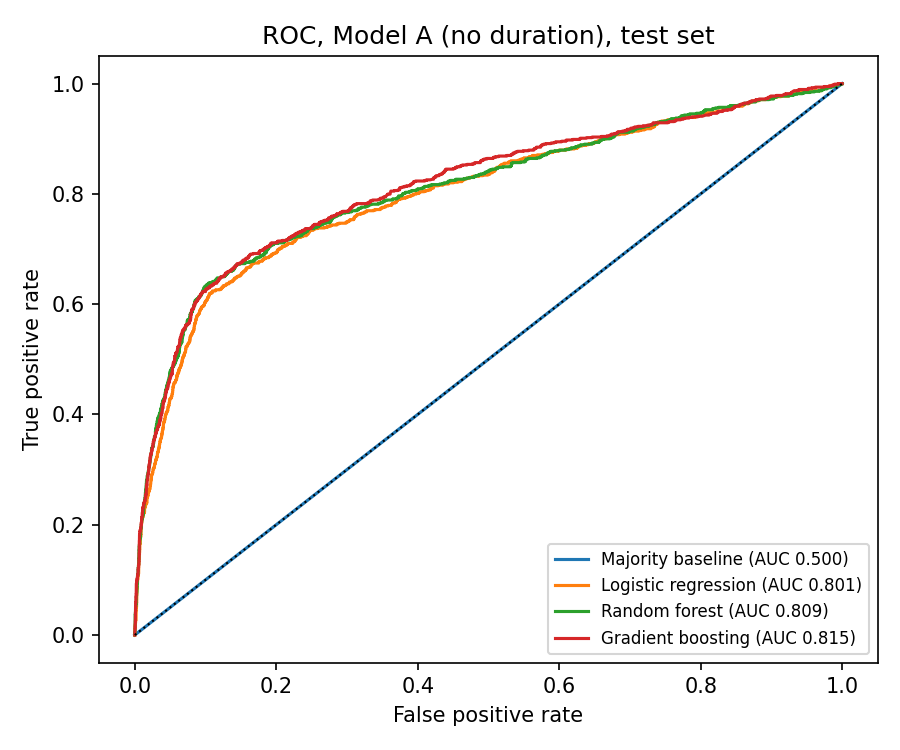

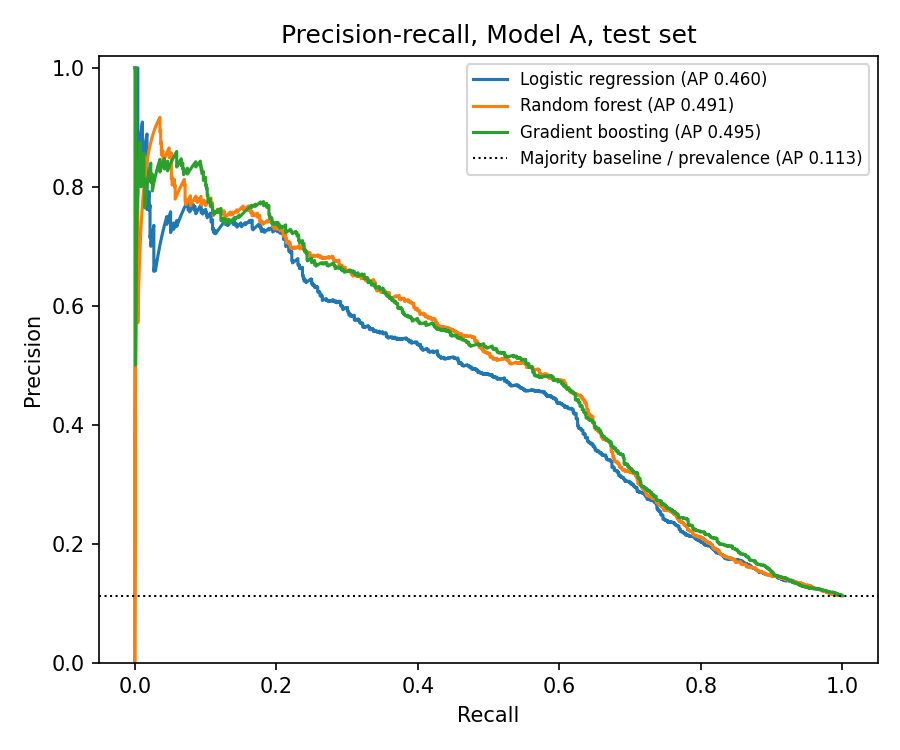

In [7]:
display(Image('../results/roc_model_a.png'), Image('../results/pr_model_a.png'))

## 6. Leakage: Model A vs Model B

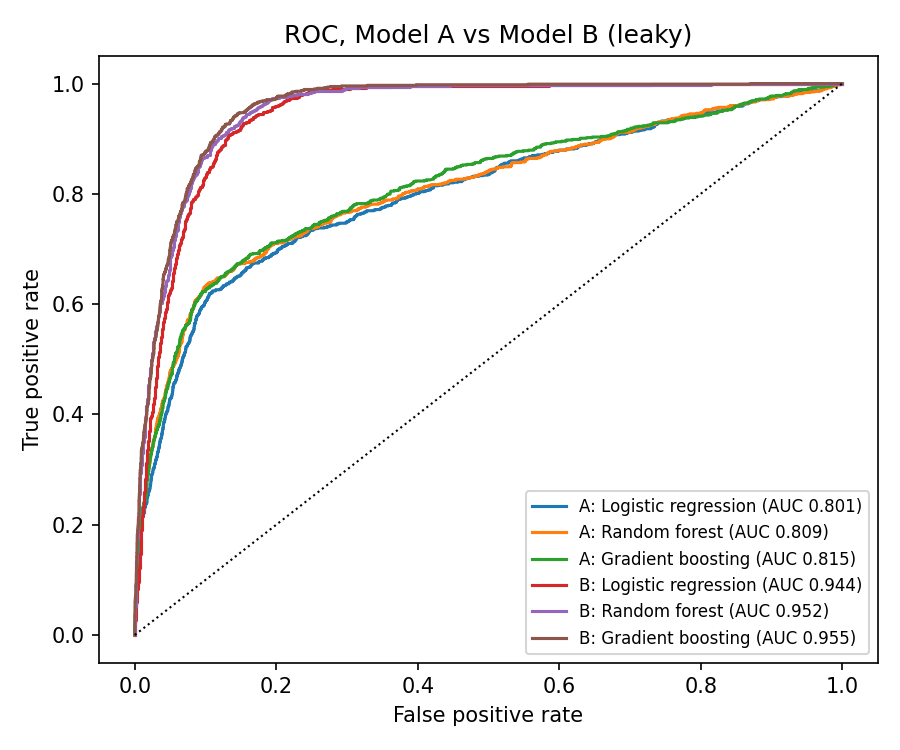

In [8]:
Image('../results/roc_a_vs_b.png')

## 7. Calibration

Balanced logistic regression is badly overconfident. Gradient boosting is already near the diagonal, and isotonic calibration changes little.

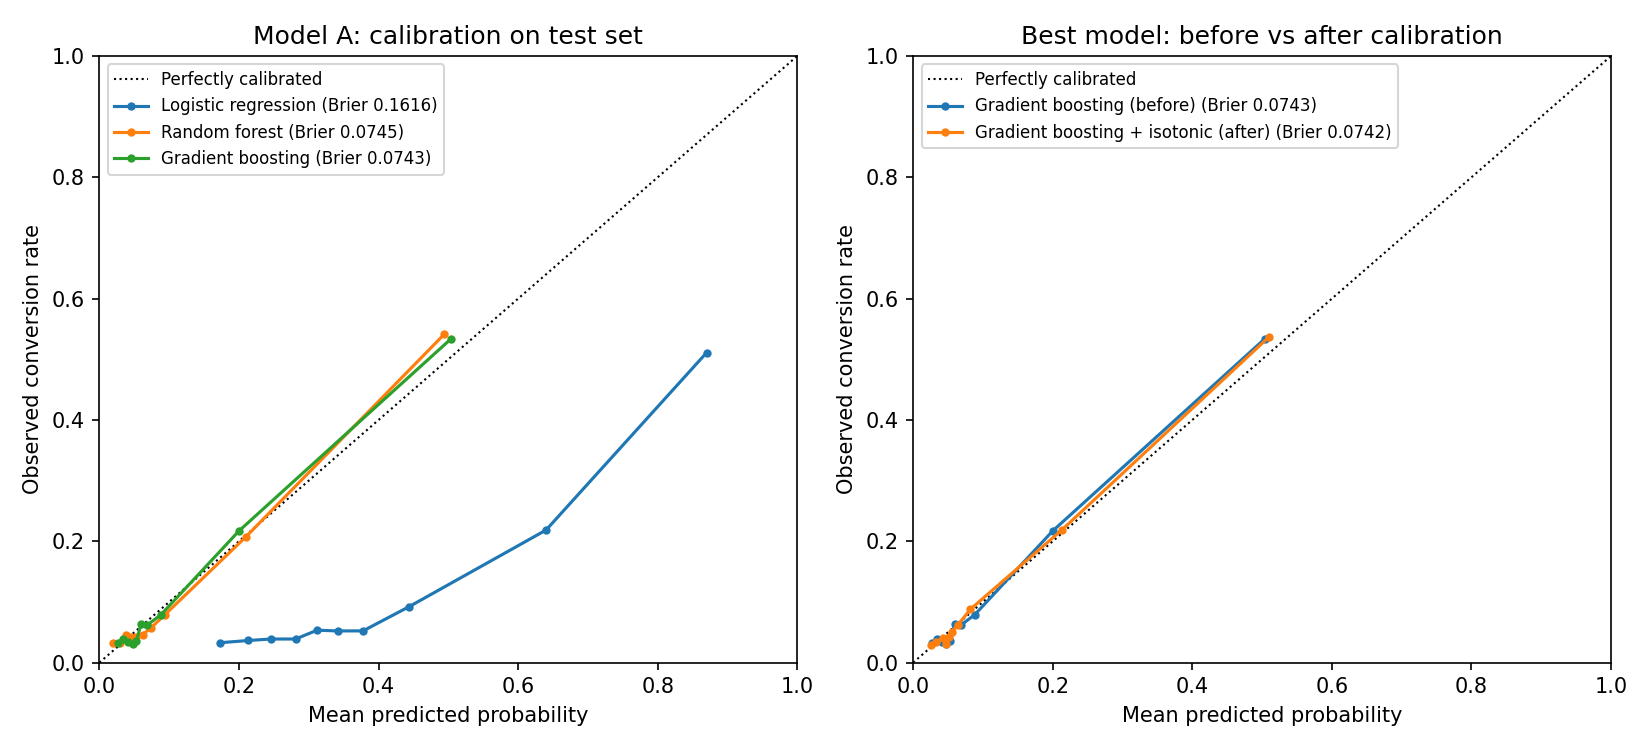

In [9]:
Image('../results/calibration_model_a.png')

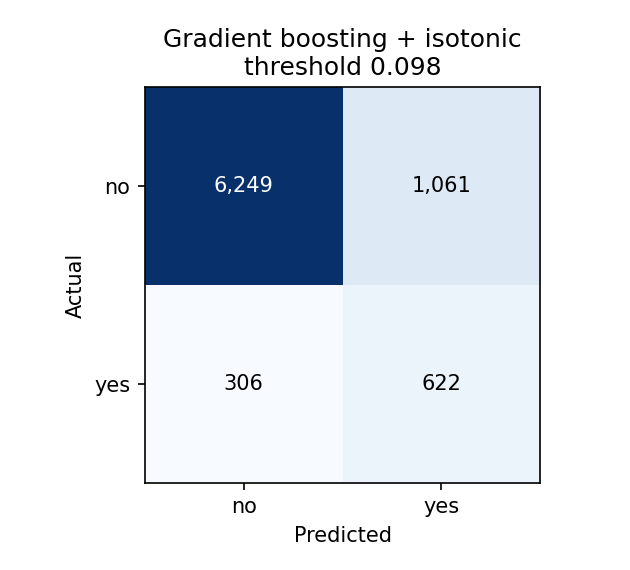

In [10]:
Image('../results/confusion_model_a.png')

## 8. What drives predictions: permutation importance on the test set

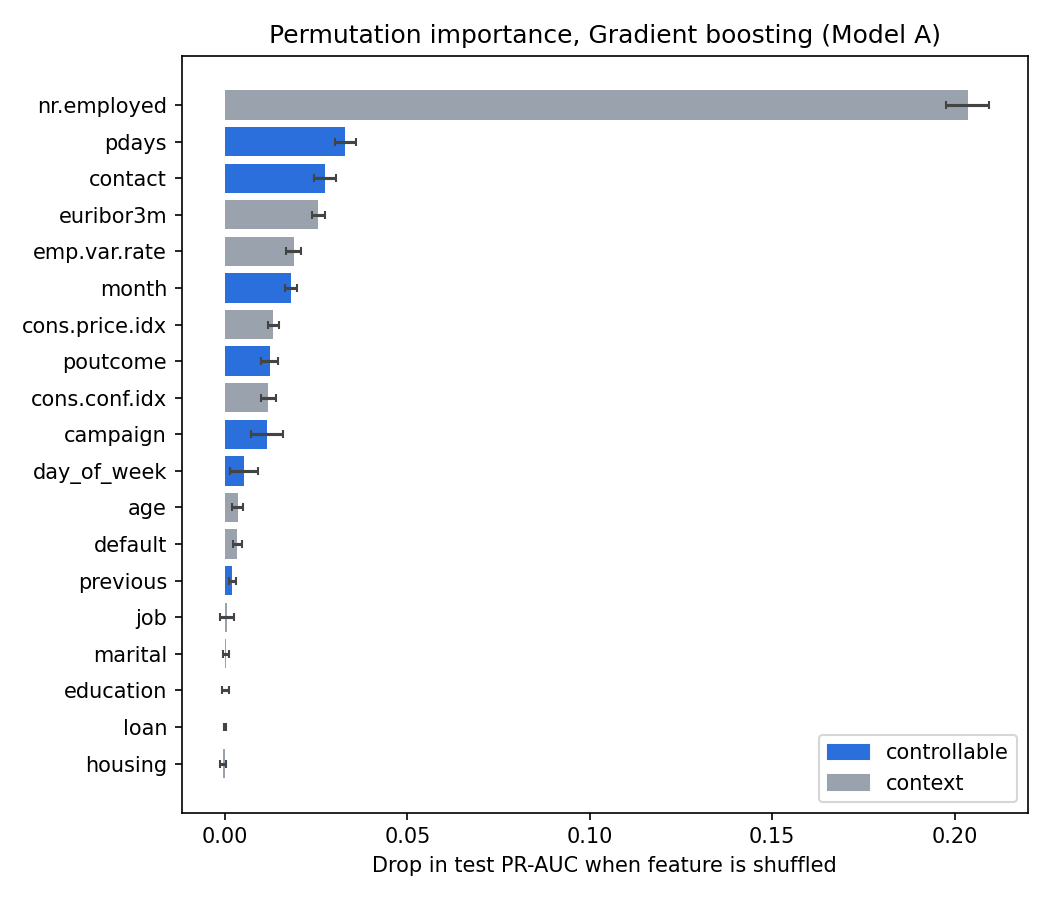

,feature,group,importance,sd,share_of_controllable
0,pdays,controllable,0.033038,0.002827,0.300737
1,contact,controllable,0.027442,0.003084,0.249802
2,month,controllable,0.018121,0.001572,0.164953
3,poutcome,controllable,0.012305,0.002293,0.112008
4,campaign,controllable,0.011653,0.004369,0.106072
5,day_of_week,controllable,0.005214,0.003948,0.047460
6,previous,controllable,0.002084,0.001001,0.018968


In [11]:
display(Image('../results/permutation_importance.png'))
pd.read_csv('../results/permutation_importance_controllable.csv')

## 9. Caveats

- Importance is **correlational, not causal**.
- The bank data is a **proxy** for home-services leads. Speed-to-lead is not in it.
- The temporal split shows the random split is optimistic, because the macro features drift.
- Tree models beat logistic regression by only about 0.02 PR-AUC.